# Tune nisjemodell usikkerhet thresholds

Interactive check of the per-axis decision-margin thresholds used by
`mnk.utils.nisje_usikkerhet` (method `NKM_nisjedata_kvalitet`).

The slow part — sampling the substrate / light / salinity margins per polygon from
the driver rasters — runs **once**. After that you can edit the thresholds and see
the resulting lav/middel/høy split instantly, with no re-sampling. When happy, paste
the values back into `USIKKERHET_SUB` / `USIKKERHET_LYS` / `USIKKERHET_SAL` in
`mnk/utils.py`.

Set `BBOX = None` to sample the whole country (slow), or pick a fjord window to
exercise the salinity axis (open coast is always far from the 18 PSU boundary).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import mnk.utils
import mnk.attributes

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

SUBPROB_PATH = "gs://niva-geodata/MarintNaturKart/results/3band_probability_calibrated.tif"
KD_PATH = "gs://niva-geodata/MarintNaturKart/results/KD490_norge_2020-2025_filled_25833.tif"
DEPTH_PATH = "gs://niva-geodata/MarintNaturKart/features/feature_norge_dem50_depth_filled.tif"
SALINITY_PATH = "gs://niva-geodata/MarintNaturKart/input/hi/Norfjords_160_surf_salt_mean_UTM33.tif"

POLY_PATH = REPO / "notebooks" / "nisjemodell_norge_2026_25833_clipped.geo.parquet"

BBOX = (200000, 7040000, 260000, 7090000)
MAX_POLYGONS = 40_000

AXES = ["substrate", "light", "salinity"]
UNITS = ["|P_soft - P_hard|", "|z_eu - depth| / z_eu", "|salinity - 18| PSU"]

## 1. Load polygons

In [2]:
if not Path(POLY_PATH).exists():
    POLY_PATH = REPO / "notebooks" / "nisjemodell_norge_2026_25833.geo.parquet"
    print(f"clipped checkpoint not found, using {POLY_PATH.name}")

poly = gpd.read_parquet(POLY_PATH)
if BBOX is not None:
    poly = poly.cx[BBOX[0]:BBOX[2], BBOX[1]:BBOX[3]]
poly = poly.reset_index(drop=True)
if len(poly) > MAX_POLYGONS:
    poly = poly.sample(MAX_POLYGONS, random_state=0).reset_index(drop=True)

if "_substrat_kilde" in poly:
    is_obs = (poly["_substrat_kilde"] == mnk.attributes.OBS_SUBSTRAT_KILDE).to_numpy()
elif "datakilde" in poly:
    is_obs = poly["datakilde"].str.contains(mnk.attributes.OBS_SUBSTRAT_KILDE, na=False).to_numpy()
else:
    is_obs = None
print(f"{len(poly):,} polygons | NGU-observed: {0 if is_obs is None else int(is_obs.sum()):,}")

clipped checkpoint not found, using nisjemodell_norge_2026_25833.geo.parquet
13,452 polygons | NGU-observed: 0


## 2. Sample the axis margins (slow — runs once)

In [3]:
margins = mnk.utils.nisje_axis_margins(
    poly,
    kd_path=KD_PATH,
    depth_path=DEPTH_PATH,
    salinity_path=SALINITY_PATH,
    subprob_path=SUBPROB_PATH,
)
valid = np.isfinite(margins).sum(1)
print("valid polygons per axis:", dict(zip(AXES, valid.tolist())))

valid polygons per axis: {'substrate': 12143, 'light': 12143, 'salinity': 10091}


## 3. Margin distributions
The dashed lines are the current `USIKKERHET_*` thresholds (green = lav floor, red = høy ceiling).

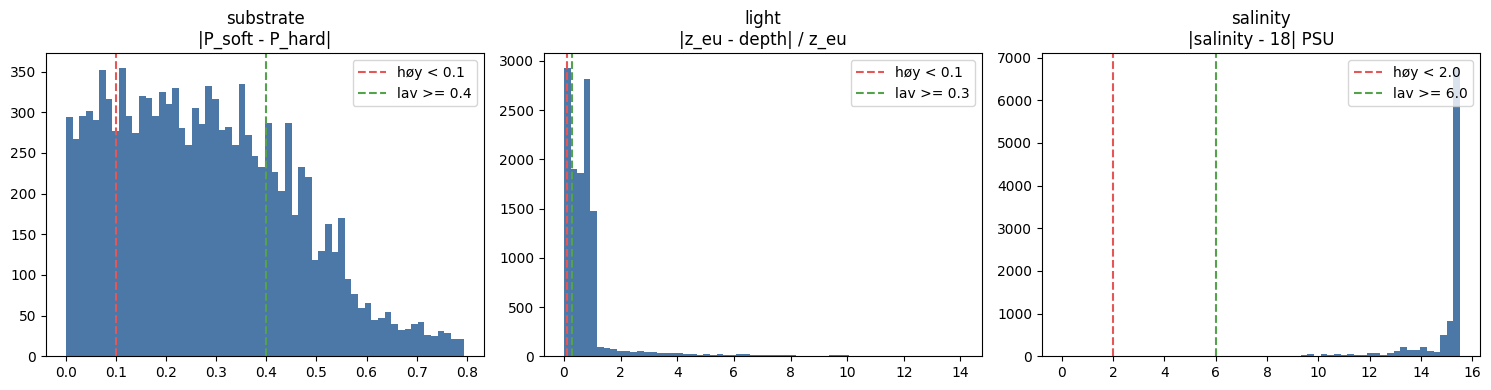

In [4]:
thr = [mnk.utils.USIKKERHET_SUB, mnk.utils.USIKKERHET_LYS, mnk.utils.USIKKERHET_SAL]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for i, (ax, name, unit, (lav, hoy)) in enumerate(zip(axs, AXES, UNITS, thr)):
    m = margins[i][np.isfinite(margins[i])]
    ax.hist(m, bins=60, range=(0, np.percentile(m, 99)), color="#4c78a8")
    ax.axvline(hoy, color="#e45756", ls="--", label=f"høy < {hoy}")
    ax.axvline(lav, color="#54a24b", ls="--", label=f"lav >= {lav}")
    ax.set_title(f"{name}\n{unit}")
    ax.legend()
fig.tight_layout()
plt.show()

## 4. Try thresholds

Edit the three `(lav, høy)` tuples and re-run this cell — it reclassifies instantly from the cached `margins` (no re-sampling). The table shows each axis on its own and the combined worst-axis result.

In [5]:
SUB = (0.40, 0.10)
LYS = (0.30, 0.10)
SAL = (10.0, 12.0)

labels = mnk.utils.usikkerhet_from_margins(margins, is_obs=is_obs, sub=SUB, lys=LYS, sal=SAL)

def share(x):
    s = pd.Series(x)
    return {k: round(100 * (s == k).mean(), 1) for k in ["lav", "medium", "høy"]}

names = np.array(["ingen", "lav", "medium", "høy"])
rows = {}
for i, (name, (lav, hoy)) in enumerate(zip(AXES, [SUB, LYS, SAL])):
    rows[name] = share(names[mnk.utils._axis_usikkerhet(margins[i], lav, hoy)])
rows["COMBINED (worst)"] = share(labels)
pd.DataFrame(rows).T[["lav", "medium", "høy"]]

,lav,medium,høy
substrate,23.9,49.5,16.9
light,64.1,16.3,9.9
salinity,73.3,0.0,1.8
COMBINED (worst),24.2,50.0,25.8


## 5. Map

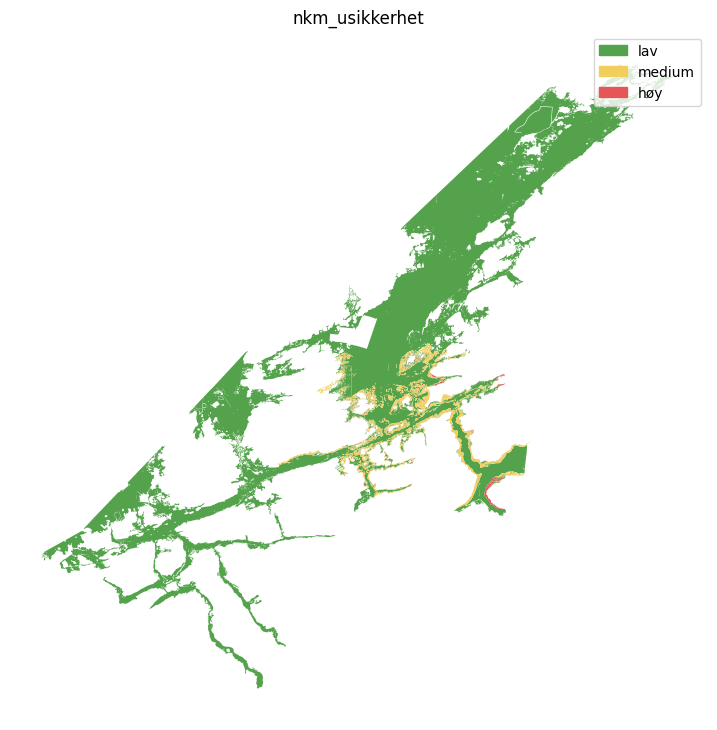

In [6]:
cmap = {"lav": "#54a24b", "medium": "#f2cf5b", "høy": "#e45756"}
ax = poly.assign(u=labels).plot(color=pd.Series(labels).map(cmap), figsize=(9, 9), linewidth=0)
ax.set_axis_off()
ax.set_title("nkm_usikkerhet")
ax.legend(handles=[mpatches.Patch(color=c, label=k) for k, c in cmap.items()])
plt.show()

## 6. Chosen thresholds\n\nPaste these into `mnk/utils.py`.

In [7]:
print(f"USIKKERHET_SUB = {SUB}")
print(f"USIKKERHET_LYS = {LYS}")
print(f"USIKKERHET_SAL = {SAL}")

USIKKERHET_SUB = (0.4, 0.1)
USIKKERHET_LYS = (0.3, 0.1)
USIKKERHET_SAL = (10.0, 12.0)
